In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
import pandas as pd
%matplotlib widget
%config InlineBackend.figure_format = 'svg'
#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5
#========================================================================================================================================
# Función principal
#========================================================================================================================================
def ejecutar(b):
    #==============================================================================================================================================================
    archivo = Path(fc.selected)
    nombre_archivo = archivo.name

    df = pd.read_csv(fc.selected, sep=',')
    fs_r = 8000
    to = 0
    tf = 50
    global tiempos
    tiempos    = df['t_ms'].values
    global señal_MBK
    señal_MBK  = df['MBK'].values
    señal_MBK  = señal_MBK - np.mean(señal_MBK)
    global señal_ACC
    señal_ACC  = -df['ACC'].values
    señal_ACC  = señal_ACC - np.mean(señal_ACC)

    señal_EGG  =  df['MBK'].values
    señal_EGG  = Funciones.Detrend(tiempos,señal_EGG)
    señal_dEGG = np.gradient(señal_EGG)
    #min_dEGG = min(señal_dEGG)
    #max_dEGG = max(señal_dEGG)
    #lim_inf_dEGG = min_dEGG*1.5
    #lim_sup_dEGG = max_dEGG*1.5  

    # ==============================================================================================================================================================
    # 
    t0_analisis = 5 #ms 
    tf_analisis = 45#ms
    mascara_tiempos = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
    global tiempos_analisis
    tiempos_analisis = tiempos[mascara_tiempos]
    global flujo_OVV
    flujo_OVV   = df['flujo_OVV'].values[mascara_tiempos]

    #flujo_OVV  = Funciones.Detrend(tiempos_ovv,flujo_OVV)
    flujo_OVV  = Funciones.Normalizar(flujo_OVV)
    global dflujo_OVV
    dflujo_OVV = np.gradient(flujo_OVV)

    # ==============================================================================================================================================================
    # Filtrado post-procesamiento de la solución (flujo/dflujo), configurable
    # y con parámetros distintos según la vocal del archivo cargado.
    aplicar_filtro = filtro_aplicar.value

    if vocal_selector.value == 'A':
        orden_filtro_pb = filtro_orden_A.value
        fc_filtro_pb    = filtro_fc_A.value
    else:
        orden_filtro_pb = filtro_orden_I.value
        fc_filtro_pb    = filtro_fc_I.value

    def filtrar_flujo(flujo, tiempos_flujo):
        """Aplica (o no, según el checkbox) el filtro pasabajos configurado
        para la vocal seleccionada, y RECIÉN DESPUÉS hace el Detrend y la
        normalización sobre la señal ya filtrada (y recalcula dflujo).

        Es importante filtrar antes de normalizar: si se normaliza primero
        (fijando el rango en [0,1]) y se filtra después, el filtro atenúa el
        cierre glótico (rápido, alta frecuencia) y el valle deja de tocar 0,
        aunque la normalización ya haya "prometido" ese rango. Filtrando
        primero, el rango [0,1] final se calcula sobre la forma real que se
        va a comparar."""
        if aplicar_filtro:
            flujo_filtrado, _, _ = Funciones.LP_Filter(flujo, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
        else:
            flujo_filtrado = flujo
        flujo_filtrado = Funciones.Detrend(tiempos_flujo, flujo_filtrado)
        flujo_filtrado = Funciones.Normalizar(flujo_filtrado)
        dflujo_filtrado = np.gradient(flujo_filtrado)
        return flujo_filtrado, dflujo_filtrado
    # ==============================================================================================================================================================
    global resultado_CONMF
    resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,
                  acelerometro=señal_ACC,
                  dEGG = señal_dEGG,
                  tiempos=tiempos,
                  mascara_tiempos=mascara_tiempos,
                  fs=fs_r,
                  norma=conmf_norma.value,
                  pre_iteraciones=conmf_pre_iteraciones.value,
                  iteraciones=conmf_iteraciones.value,
                  T = conmf_T.value,
                  delta = conmf_delta.value,
                  p_filtro_speech=conmf_p_filtro_speech.value,
                  alfa_speech=conmf_alfa_speech.value,
                  p_filtro_acc=conmf_p_filtro_acc.value,
                  alfa_acc=conmf_alfa_acc.value,
                  beta_speech=conmf_beta_speech.value,
                  beta_acc= conmf_beta_acc.value,
                  pre_enfasis_speech=conmf_pre_enfasis_speech.value,
                  pre_enfasis_acc=conmf_pre_enfasis_acc.value,
                  duracion=conmf_duracion_ventana.value,
                  guardar_proceso=conmf_guardar_proceso.value,
                  normalizar_espectrogramas=conmf_normalizar_espectrogramas.value,
                  ventana = conmf_ventana.value
    )
    resultado_CONMF.flujo1_speech, resultado_CONMF.dflujo1_speech = filtrar_flujo(
        resultado_CONMF.flujo1_speech, resultado_CONMF.tiempos_gve_speech
    )

    resultado_CONMF.flujo2_speech, resultado_CONMF.dflujo2_speech = filtrar_flujo(
        resultado_CONMF.flujo2_speech, resultado_CONMF.tiempos_gve_speech
    )

    resultado_CONMF.flujo1_acc, resultado_CONMF.dflujo1_acc = filtrar_flujo(
        resultado_CONMF.flujo1_acc, resultado_CONMF.tiempos_gve_acc
    )

    resultado_CONMF.flujo2_acc, resultado_CONMF.dflujo2_acc = filtrar_flujo(
        resultado_CONMF.flujo2_acc, resultado_CONMF.tiempos_gve_acc
    )
    
    global resultado_NMF_speech
    resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,
                                        dEGG = señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos=mascara_tiempos,
                                        fs=fs_r,
                                        norma=nmf_norma.value,
                                        pre_iteraciones=nmf_pre_iteraciones.value,
                                        iteraciones=nmf_iteraciones.value,
                                        T = nmf_T.value,
                                        delta = nmf_delta.value,
                                        p_filtro=nmf_p_filtro_speech.value,
                                        alfa=nmf_alfa_speech.value,
                                        beta=nmf_beta_speech.value,
                                        pre_enfasis=nmf_pre_enfasis_speech.value,
                                        duracion=nmf_duracion_ventana.value,
                                        guardar_proceso=nmf_guardar_proceso.value,
                                        ventana = nmf_ventana.value
                                        )
    resultado_NMF_speech.flujo1, resultado_NMF_speech.dflujo1 = filtrar_flujo(
        resultado_NMF_speech.flujo1, resultado_NMF_speech.tiempos_gve
    )

    resultado_NMF_speech.flujo2, resultado_NMF_speech.dflujo2 = filtrar_flujo(
        resultado_NMF_speech.flujo2, resultado_NMF_speech.tiempos_gve
    )


    global resultado_NMF_acc
    resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,
                                        dEGG = señal_dEGG,
                                        tiempos=tiempos,
                                        mascara_tiempos=mascara_tiempos,
                                        fs=fs_r,
                                        norma=nmf_norma.value,
                                        pre_iteraciones=nmf_pre_iteraciones.value,
                                        iteraciones=nmf_iteraciones.value,
                                        T = nmf_T.value,
                                        delta = nmf_delta.value,
                                        p_filtro=nmf_p_filtro_acc.value,
                                        alfa=nmf_alfa_acc.value,
                                        beta=nmf_beta_acc.value,
                                        pre_enfasis=nmf_pre_enfasis_acc.value,
                                        duracion=nmf_duracion_ventana.value,
                                        guardar_proceso=nmf_guardar_proceso.value,
                                        ventana = nmf_ventana.value
                                        )
    
    resultado_NMF_acc.flujo1, resultado_NMF_acc.dflujo1 = filtrar_flujo(
        resultado_NMF_acc.flujo1, resultado_NMF_acc.tiempos_gve
    )

    resultado_NMF_acc.flujo2, resultado_NMF_acc.dflujo2 = filtrar_flujo(
        resultado_NMF_acc.flujo2, resultado_NMF_acc.tiempos_gve
    )
    
    plt.close('all')
    with tab_señales_originales:
        clear_output(wait=True)
        fig = plt.figure(figsize=(13,16))
        fig.canvas.header_visible = False
        widths  = [1,0.5,0.5,1]
        heights = [0.5,1,1.5,0.5]
        gs  = fig.add_gridspec(4, 4,width_ratios=widths,height_ratios=heights,wspace=0.65,top=1)
        plt.tight_layout() 
        # Señales temporales
        ax0 = fig.add_subplot(gs[0,0:2])
        ax1 = fig.add_subplot(gs[0,2:])
        # Espectrogramas
        ax2 = fig.add_subplot(gs[1,0:2])
        ax3 = fig.add_subplot(gs[1,2:])
        # Espectrograma
        ax4 = fig.add_subplot(gs[2,:])
        # Espectrograma aproximado
        ax5 = fig.add_subplot(gs[3,:])
        #=========================== Speech y ACC
        ax0.plot(tiempos,señal_MBK,color=color_speech,label='MBK')
        ax0.legend(loc=legend_loc)
        ax0.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax0.set_xlabel('Tiempo [ms]') 
        ax0.set_xlim([0,50])
        # ------------- ACC
        ax1.plot(tiempos,señal_ACC,color=color_ACC,label='ACC')
        ax1.legend(loc=legend_loc)
        ax1.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax1.set_xlabel('Tiempo [ms]') 
        ax1.set_xlim([0,50])
        #========================= Espectrograma speech
        im2 = ax2.imshow(resultado_CONMF.espectrograma_speech_original,
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_CONMF.to_espectrograma_original, resultado_CONMF.tf_espectrograma_original,
                                resultado_CONMF.fo_espectrograma, resultado_CONMF.ff_espectrograma])
        ax2.set_ylabel('Frecuencia [Hz]')
        ax2.set_xlabel("Tiempo [ms]")
        #fig.colorbar(im2, ax=ax2, pad=0.02)
        # ------------- dEGG
        ''' 
        ax2_ = ax2.twinx()
        ax2_.plot(resultado_CONMF.tiempos_espectrograma_original,resultado_CONMF.dEGG_original,color='white', label=r"$dEGG$", linewidth=line_width)
        ax2_.legend(loc=legend_loc)
        ax2_.set_xlim(resultado_CONMF.to_espectrograma_original, resultado_CONMF.tf_espectrograma_original)
        ax2_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax2_.set_xticks(np.arange(resultado_CONMF.to_espectrograma_original, resultado_CONMF.tf_espectrograma_original, resultado_CONMF.duracion_ventana))
        ax2_.set_yticks([])
        '''
        #========================= Espectrograma ACC
        im3 = ax3.imshow(resultado_CONMF.espectrograma_acc_original,
                        cmap = cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original,
                                resultado_CONMF.fo_espectrograma,resultado_CONMF.ff_espectrograma]);
        ax3.set_ylabel('Frecuencia [Hz]')
        bbox = ax3.get_position()
        width = 0.015
        eps = 0.01
        cax = fig.add_axes([bbox.x1 + eps, bbox.y0, width, bbox.height])
        fig.colorbar(im3, cax=cax)

        # ------------- dEGG
        '''
        ax3_ = ax3.twinx()
        ax3_.plot(resultado_CONMF.tiempos_espectrograma_original,resultado_CONMF.dEGG_original,color='white',label=r"$dEGG$",linewidth=line_width);
        ax3_.legend(loc=legend_loc);
        ax3_.set_xlim(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original)
        ax3_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax3_.set_xticks(np.arange(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original,resultado_CONMF.duracion_ventana))
        ax3_.set_yticks([])
        ax3.set_xlabel('Tiempo [ms]')
        '''
        #========================= Espectrograma combinado
        im4 = ax4.imshow(resultado_CONMF.espectrograma_plot_original,
                        cmap = cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original,
                                resultado_CONMF.fo_espectrograma,2*resultado_CONMF.ff_espectrograma])
        yticks = [0, 2000, 4000, 6000, 8000]
        ax4.set_yticks(yticks)
        bbox = ax4.get_position()
        width = 0.015
        eps = 0.01
        # Nuevo eje para la barra de colores
        # [x0, y0, ancho, alto]
        cax = fig.add_axes([bbox.x1 + eps, bbox.y0, width, bbox.height])
        fig.colorbar(im4, cax=cax)
        ax4.set_yticklabels(['0', '2000', '4000', '2000', '4000'])
        ax4.set_ylabel('Frecuencia [Hz]')
        # ------------- dEGG
        '''   
        ax4_ = ax4.twinx()
        ax4_.plot(resultado_CONMF.tiempos_espectrograma_original,resultado_CONMF.dEGG_original,color='white',label=r"$dEGG$",linewidth=line_width);
        ax4_.legend(loc='upper right')
        ax4_.set_xlim(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original)
        ax4_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax4_.set_xticks(np.arange(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original,resultado_CONMF.duracion_ventana))
        ax4_.set_yticks([])
        ax4.set_xlabel('Tiempo [ms]')
        '''
        #========================= Energías
        ax5.plot(resultado_CONMF.tiempos_espectrograma_original,resultado_CONMF.energia_speech_original,color=color_speech,label=r"Speech",linewidth=line_width);
        ax5.plot(resultado_CONMF.tiempos_espectrograma_original,resultado_CONMF.energia_acc_original,color=color_ACC,label=r"ACC",linewidth=line_width);
        ax5.legend(loc=legend_loc);
        ax5.set_xlim(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original)
        ax5.set_ylim([0,1.5])
        ax5.set_xticks(np.arange(resultado_CONMF.to_espectrograma_original,resultado_CONMF.tf_espectrograma_original,resultado_CONMF.duracion_ventana))
        ax5.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax5.set_xlabel('Tiempo [ms]')   
        ax5.set_ylabel('Energía')  
        plt.show()

    with tab_resultados_frecuencia:
        clear_output(wait=True)

        fig = plt.figure(figsize=(13,16))
        fig.canvas.header_visible = False
        widths  = [1,0.5]
        heights = [1,1,0.5,0.75,0.75]
        gs  = fig.add_gridspec(5, 2,width_ratios=widths,height_ratios=heights,top=0.97,wspace=0.15,hspace=0.25)

        # Espectrograma
        ax1 = fig.add_subplot(gs[0,:])
        # Espectrograma aproximado
        ax2 = fig.add_subplot(gs[1,:])
        # Activacion
        ax3 = fig.add_subplot(gs[2,:])
        # Resp frecuencia y polos y ceros
        ax4 = fig.add_subplot(gs[3,0])
        ax5 = fig.add_subplot(gs[3,1])
        # Resp frecuencia y polos y ceros
        ax6  = fig.add_subplot(gs[4,0])
        ax7 = fig.add_subplot(gs[4,1])

        #========================= Espectrograma sincronizado
        im1 = ax1.imshow(resultado_CONMF.espectrograma_plot_sincronizado,
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado,
                                resultado_CONMF.fo_espectrograma, resultado_CONMF.ff_espectrograma])
        ax1.set_ylabel('Frecuencia [Hz]')
        ax1.set_xlabel("Tiempo [ms]")
        bbox = ax1.get_position()
        width = 0.015
        eps = 0.01
        cax = fig.add_axes([bbox.x1 + eps, bbox.y0, width, bbox.height])
        fig.colorbar(im1, cax=cax)
        ax1.set_title(f'Desfasaje corregido: {abs(resultado_CONMF.lag)} muestras')
        # ------------- dEGG
        '''
        ax1_ = ax1.twinx()
        ax1_.plot(resultado_CONMF.tiempos_espectrograma_sincronizado,resultado_CONMF.dEGG_sincronizado,color='white', label=r"$dEGG$", linewidth=line_width)
        ax1_.legend(loc=legend_loc)
        ax1_.set_xlim(resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado)
        ax1_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax1_.set_xticks(np.arange(resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado, resultado_CONMF.duracion_ventana))
        ax1_.set_yticks([])
        '''
        #========================= Espectrograma aproximado sincronizado
        im2 = ax2.imshow(resultado_CONMF.espectrograma_aprox_plot,
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado,
                                resultado_CONMF.fo_espectrograma, resultado_CONMF.ff_espectrograma])
        ax2.set_ylabel('Frecuencia [Hz]')
        ax2.set_xlabel("Tiempo [ms]")
        bbox = ax2.get_position()
        width = 0.015
        eps = 0.01
        cax = fig.add_axes([bbox.x1 + eps, bbox.y0, width, bbox.height])
        fig.colorbar(im2, cax=cax)
        # ------------- dEGG
        ''' 
        ax2_ = ax2.twinx()
        ax2_.plot(resultado_CONMF.tiempos_espectrograma_sincronizado,resultado_CONMF.dEGG_sincronizado,color='white', label=r"$dEGG$", linewidth=line_width)
        ax2_.legend(loc=legend_loc)
        ax2_.set_xlim(resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado)
        ax2_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax2_.set_xticks(np.arange(resultado_CONMF.to_espectrograma_sincronizado, resultado_CONMF.tf_espectrograma_sincronizado, resultado_CONMF.duracion_ventana))
        ax2_.set_yticks([])
        '''

        #========================= Funciones de activación
        ax3.plot(resultado_CONMF.tiempos_espectrograma_sincronizado,resultado_CONMF.H1,color=color1,label=r'$H_1$')
        ax3.plot(resultado_CONMF.tiempos_espectrograma_sincronizado,resultado_CONMF.H2,color=color2,label=r'$H_2$')
        ax3.set_xlim(resultado_CONMF.to_espectrograma_sincronizado,resultado_CONMF.tf_espectrograma_sincronizado)
        ax3.set_xticks(np.arange(resultado_CONMF.to_espectrograma_sincronizado,resultado_CONMF.tf_espectrograma_sincronizado,resultado_CONMF.duracion_ventana))
        ax3.set_xticks(np.arange(resultado_CONMF.to_espectrograma_sincronizado,resultado_CONMF.tf_espectrograma_sincronizado,resultado_CONMF.duracion_ventana/2),minor=True)
        ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax3.legend(loc=legend_loc)
        ax3.set_xlabel('Tiempo [ms]')
        #========================= Respuesta en frecuencia/polos-ceros speech
        # ------------- Respuesta en frecuencia
        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],resultado_CONMF.a_W1_speech,fs=fs_r)
        fw2,hw2 = sig.freqz([1],resultado_CONMF.a_W2_speech,fs=fs_r)
        ax4.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
        ax4.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
        ax4.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
        ax4.set_xlim(0,fs_r/2)
        ax4.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
        ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
        ax4.set_xlabel('Frecuencia [Hz]')
        ax4.set_ylabel('[dB]')
        ax4.set_ylim([-30,20])
        ax4.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax5.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        ax5.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
        ax5.yaxis.tick_right()
        ax5.yaxis.set_label_position("right")
        ax5.scatter(np.real(resultado_CONMF.ceros_W1_speech), np.imag(resultado_CONMF.ceros_W1_speech),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax5.scatter(np.real(resultado_CONMF.polos_W1_speech), np.imag(resultado_CONMF.polos_W1_speech),s=80, marker='x', color=color1, label='Polos')
        ax5.scatter(np.real(resultado_CONMF.ceros_W2_speech), np.imag(resultado_CONMF.ceros_W2_speech),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax5.scatter(np.real(resultado_CONMF.polos_W2_speech), np.imag(resultado_CONMF.polos_W2_speech),s=80, marker='x', color=color2, label='Polos')
        ax5.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax5.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax5.set_ylabel(r"$Im\{z\}$")
        ax5.set_xlabel(r"$Re\{z\}$")
        ax5.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        #========================= Respuesta en frecuencia/polos-ceros ACC
        # ------------- Respuesta en frecuencia
        fftseñal, fseñal = Funciones.FFT(señal_ACC, fs_r)
        fw1,hw1 = sig.freqz([1],resultado_CONMF.a_W1_acc,fs=fs_r)
        fw2,hw2 = sig.freqz([1],resultado_CONMF.a_W2_acc,fs=fs_r)
        ax6.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
        ax6.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
        ax6.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='acc', color=color3, zorder=-1)
        ax6.set_xlim(0,fs_r/2)
        ax6.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
        ax6.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
        ax6.set_xlabel('Frecuencia [Hz]')
        ax6.set_ylabel('[dB]')
        ax6.set_ylim([-30,20])
        ax6.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax7.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        ax7.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
        ax7.yaxis.tick_right()
        ax7.yaxis.set_label_position("right")
        ax7.scatter(np.real(resultado_CONMF.ceros_W1_acc), np.imag(resultado_CONMF.ceros_W1_acc),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax7.scatter(np.real(resultado_CONMF.ceros_W2_acc), np.imag(resultado_CONMF.ceros_W2_acc),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax7.scatter(np.real(resultado_CONMF.polos_W1_acc), np.imag(resultado_CONMF.polos_W1_acc),s=80, marker='x', color=color1, label='Polos')
        ax7.scatter(np.real(resultado_CONMF.polos_W2_acc), np.imag(resultado_CONMF.polos_W2_acc),s=80, marker='x', color=color2, label='Polos')
        ax7.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax7.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax7.set_ylabel(r"$Im\{z\}$")
        ax7.set_xlabel(r"$Re\{z\}$")
        ax7.grid(True, linestyle='dashed', color='gray', alpha=0.3)
            
        plt.show()
   
    with tab_detalle_nmf:
        clear_output(wait=True)  
        fig, ax = plt.subplots(4, 1, figsize=(13, 12))
        fig.canvas.header_visible = False
        fig.subplots_adjust(hspace=0.35,top=0.97)

        ax[0].plot(resultado_CONMF.error_NNMF, color='orange', label='Error')
        ax0_ = ax[0].twinx()
        ax0_.plot(resultado_CONMF.dif_error_X*100, color='green', label='Δ Error')
        ax0_.set_ylim([-0.5,2])
        ax[0].set_ylabel('Error')
        ax0_.set_ylabel('Δ Error [%]')
        ax[0].set_xlabel('Iteración n°')
        h1, l1 = ax[0].get_legend_handles_labels()
        h2, l2 = ax0_.get_legend_handles_labels()
        ax[0].legend(h1 + h2, l1 + l2, loc=legend_loc,)
        ax[0].set_title("Cantidad de iteraciones realizadas: "+str(resultado_CONMF.n_iteraciones))

        ax[1].plot(resultado_CONMF.dif_error_H1*100, color=color1, label='Δ H1')
        ax[1].plot(resultado_CONMF.dif_error_H2*100, color=color2, label='Δ H2')
        ax[1].set_ylabel('Δ [%]')
        ax[1].set_ylim([0,2])
        ax[1].legend(loc=legend_loc)
        ax[1].set_xlabel('Iteración n°')

        ax[2].plot(resultado_CONMF.dif_error_W1_speech*100, color=color1, label='Δ W1 - speech')
        ax[2].plot(resultado_CONMF.dif_error_W2_speech*100, color=color2, label='Δ W2 - speech')
        ax[2].plot(resultado_CONMF.dif_error_W1_acc*100,linestyle='dashed',color=color1, label='Δ W1 - acc')
        ax[2].plot(resultado_CONMF.dif_error_W2_acc*100,linestyle='dashed',color=color2, label='Δ W2 - acc')
        ax[2].set_ylabel('Δ [%]')
        ax[2].set_ylim([0,1])
        ax[2].legend(loc=legend_loc)
        ax[2].set_xlabel('Iteración n°')

        ax[3].plot(resultado_CONMF.dif_error_X*100, color='green', label='Δ Error')
        ax[3].plot(resultado_CONMF.dif_error_H1*100, color=color1, label='Δ H1')
        ax[3].plot(resultado_CONMF.dif_error_H2*100, color=color2, label='Δ H2')
        ax[3].set_ylim([0,2])
        ax[3].legend(loc=legend_loc)

        ax[3].plot(resultado_CONMF.dif_error_W1_speech*100, label='Δ W1 - speech')
        ax[3].plot(resultado_CONMF.dif_error_W2_speech*100, label='Δ W2 - speech')
        ax[3].plot(resultado_CONMF.dif_error_W1_acc*100,linestyle='dashed', label='Δ W1 - acc')
        ax[3].plot(resultado_CONMF.dif_error_W2_acc*100,linestyle='dashed',label='Δ W2 - acc')
        ax[3].set_ylabel('Δ [%]')
        ax[3].set_ylim([0,1])
        ax[3].legend(loc=legend_loc)
        ax[3].set_xlabel('Iteración n°')
        plt.show()

    with tab_criterio_seleccion:
        clear_output(wait=True)
        fig,ax = plt.subplots(4,figsize=(13,12))
        fig.canvas.header_visible = False
        fig.subplots_adjust(hspace=0.35,top=0.97)
        ax[0].plot(resultado_CONMF.tiempos_gve_speech,resultado_CONMF.error_predic1_speech,color=color1,label=r'$e_1(t) - speech$');
        ax[0].plot(resultado_CONMF.tiempos_gve_speech,resultado_CONMF.error_predic2_speech,color=color2,label=r'$e_2(t) - speech$');
        ax[0].set_xlim([to,tf]);
        ax[0].set_xticks(np.arange(to,tf,2.5),minor=True)
        ax[0].tick_params(axis='x', which='both')
        ax[0].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax[0].set_xlabel('Tiempo [ms]');
        ax[0].legend(loc=legend_loc)

        ax[1].plot(resultado_CONMF.tiempos_eH_speech,resultado_CONMF.e1H1_speech,color=color1,label=r"$H_1(t)|e_1(t)|$"+"  ~ " + r"$\frac{\sum H_1(t)|e_1(t)|}{\sum H_1(t)}=$"+f"{round(resultado_CONMF.suma_e1H1_speech,6)}")
        ax[1].plot(resultado_CONMF.tiempos_eH_speech,resultado_CONMF.e2H2_speech,color=color2,label=r"$H_2(t)|e_2(t)|$"+"  ~ " + r"$\frac{\sum H_2(t)|e_2(t)|}{\sum H_2(t)}=$"+f"{round(resultado_CONMF.suma_e2H2_speech,6)}")
        ax[1].set_xlim([to,tf]);
        ax[1].set_xticks(np.arange(to,tf,2.5),minor=True)
        ax[1].tick_params(axis='x', which='both')
        ax[1].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax[1].set_xlabel('Tiempo [ms]');
        ax[1].legend(loc=legend_loc)

        ax[2].plot(resultado_CONMF.tiempos_gve_acc,resultado_CONMF.error_predic1_acc,color=color1,label=r'$e_1(t) - acc$');
        ax[2].plot(resultado_CONMF.tiempos_gve_acc,resultado_CONMF.error_predic2_acc,color=color2,label=r'$e_2(t) - acc$');
        ax[2].set_xlim([to,tf]);
        ax[2].set_xticks(np.arange(to,tf,2.5),minor=True)
        ax[2].tick_params(axis='x', which='both')
        ax[2].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax[2].set_xlabel('Tiempo [ms]');
        ax[2].legend(loc=legend_loc)
        
        ax[3].plot(resultado_CONMF.tiempos_eH_acc,resultado_CONMF.e1H1_acc,color=color1,label=r"$H_1(t)|e_1(t)|$"+"  ~ " + r"$\frac{\sum H_1(t)|e_1(t)|}{\sum H_1(t)}=$"+f"{round(resultado_CONMF.suma_e1H1_acc,6)}")
        ax[3].plot(resultado_CONMF.tiempos_eH_acc,resultado_CONMF.e2H2_acc,color=color2,label=r"$H_2(t)|e_2(t)|$"+"  ~ " + r"$\frac{\sum H_2(t)|e_2(t)|}{\sum H_2(t)}=$"+f"{round(resultado_CONMF.suma_e2H2_acc,6)}")
        ax[3].set_xlim([to,tf]);
        ax[3].set_xticks(np.arange(to,tf,2.5),minor=True)
        ax[3].tick_params(axis='x', which='both')
        ax[3].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax[3].set_xlabel('Tiempo [ms]');
        ax[3].legend(loc=legend_loc)

        plt.show()

    with tab_resultados_frecuencia_nmf:
        clear_output(wait=True)

        fig = plt.figure(figsize=(13,16))
        fig.canvas.header_visible = False
        widths  = [1,1,1,1]
        heights = [1,0.5,0.65,0.65]
        gs  = fig.add_gridspec(4, 4,width_ratios=widths,height_ratios=heights,top=0.97,wspace=0.40,hspace=0.25)

        # Espectrograma speech
        ax1 = fig.add_subplot(gs[0,:2])
        # Espectrograma acc
        ax2 = fig.add_subplot(gs[0,2:])
        # Activacion speech
        ax3 = fig.add_subplot(gs[1,:2])
        # Activacion acc
        ax4 = fig.add_subplot(gs[1,2:])
        # Resp frecuencia y polos y ceros speech
        ax5 = fig.add_subplot(gs[2,:3])
        ax6 = fig.add_subplot(gs[2,3])
        # Resp frecuencia y polos y ceros acc
        ax7  = fig.add_subplot(gs[3,:3])
        ax8 = fig.add_subplot(gs[3,3])

        #========================= Espectrograma speech
        im1 = ax1.imshow(resultado_NMF_speech.espectrograma_aprox,
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_NMF_speech.to_espectrograma, resultado_NMF_speech.tf_espectrograma,
                                resultado_NMF_speech.fo_espectrograma, resultado_NMF_speech.ff_espectrograma])
        ax1.set_ylabel('Frecuencia [Hz]')
        ax1.set_xlabel("Tiempo [ms]")
        ax1.set_title("Speech")
        # ------------- dEGG
        ''' 
        ax1_ = ax1.twinx()
        ax1_.plot(tiempos,señal_dEGG,color='white', label=r"$dEGG$", linewidth=line_width)
        ax1_.legend(loc=legend_loc)
        ax1_.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
        ax1_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax1_.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
        ax1_.set_yticks([])
        '''
        #========================= Espectrograma acc
        im2 = ax2.imshow(resultado_NMF_acc.espectrograma_aprox,
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_NMF_acc.to_espectrograma, resultado_NMF_acc.tf_espectrograma,
                                resultado_NMF_acc.fo_espectrograma, resultado_NMF_acc.ff_espectrograma])
        ax2.set_ylabel('Frecuencia [Hz]')
        ax2.set_xlabel("Tiempo [ms]")
        ax2.set_title("ACC")
        bbox = ax2.get_position()
        width = 0.015
        eps = 0.01
        cax = fig.add_axes([bbox.x1 + eps, bbox.y0, width, bbox.height])
        fig.colorbar(im1, cax=cax)
        # ------------- dEGG
        '''
        ax2_ = ax2.twinx()
        ax2_.plot(tiempos,señal_dEGG,color='white', label=r"$dEGG$", linewidth=line_width)
        ax2_.legend(loc=legend_loc)
        ax2_.set_xlim(resultado_NMF_acc.to_espectrograma,resultado_NMF_acc.tf_espectrograma)
        ax2_.set_ylim([lim_inf_dEGG,lim_sup_dEGG])
        ax2_.set_xticks(np.arange(resultado_NMF_acc.to_espectrograma,resultado_NMF_acc.tf_espectrograma, resultado_NMF_acc.duracion_ventana))
        ax2_.set_yticks([])
        ''' 
        #========================= Funciones de activación speech
        ax3.plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.H1,color=color1,label=r'$H_1$')
        ax3.plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.H2,color=color2,label=r'$H_2$')
        ax3.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
        ax3.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana))
        ax3.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana/2),minor=True)
        ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax3.legend(loc=legend_loc)
        ax3.set_xlabel('Tiempo [ms]')

        #========================= Funciones de activación acc
        ax4.plot(resultado_NMF_acc.tiempos_espectrograma,resultado_NMF_acc.H1,color=color1,label=r'$H_1$')
        ax4.plot(resultado_NMF_acc.tiempos_espectrograma,resultado_NMF_acc.H2,color=color2,label=r'$H_2$')
        ax4.set_xlim(resultado_NMF_acc.to_espectrograma,resultado_NMF_acc.tf_espectrograma)
        ax4.set_xticks(np.arange(resultado_NMF_acc.to_espectrograma,resultado_NMF_acc.tf_espectrograma,resultado_NMF_acc.duracion_ventana))
        ax4.set_xticks(np.arange(resultado_NMF_acc.to_espectrograma,resultado_NMF_acc.tf_espectrograma,resultado_NMF_acc.duracion_ventana/2),minor=True)
        ax4.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax4.legend(loc=legend_loc)
        ax4.set_xlabel('Tiempo [ms]')

        #========================= Respuesta en frecuencia/polos-ceros speech
        # ------------- Respuesta en frecuencia
        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],resultado_NMF_speech.a_W1,fs=fs_r)
        fw2,hw2 = sig.freqz([1],resultado_NMF_speech.a_W2,fs=fs_r)
        ax5.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
        ax5.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
        ax5.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
        ax5.set_xlim(0,fs_r/2)
        ax5.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
        ax5.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
        ax5.set_xlabel('Frecuencia [Hz]')
        ax5.set_ylabel('[dB]')
        ax5.set_ylim([-30,20])
        ax5.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax6.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        ax6.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
        ax6.yaxis.tick_right()
        ax6.yaxis.set_label_position("right")
        ax6.scatter(np.real(resultado_NMF_speech.ceros_W1), np.imag(resultado_NMF_speech.ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax6.scatter(np.real(resultado_NMF_speech.polos_W1), np.imag(resultado_NMF_speech.polos_W1),s=80, marker='x', color=color1, label='Polos')
        ax6.scatter(np.real(resultado_NMF_speech.ceros_W2), np.imag(resultado_NMF_speech.ceros_W2),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax6.scatter(np.real(resultado_NMF_speech.polos_W2), np.imag(resultado_NMF_speech.polos_W2),s=80, marker='x', color=color2, label='Polos')
        ax6.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax6.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax6.set_ylabel(r"$Im\{z\}$")
        ax6.set_xlabel(r"$Re\{z\}$")
        ax6.grid(True, linestyle='dashed', color='gray', alpha=0.3)

        #========================= Respuesta en frecuencia/polos-ceros acc
        # ------------- Respuesta en frecuencia
        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],resultado_NMF_acc.a_W1,fs=fs_r)
        fw2,hw2 = sig.freqz([1],resultado_NMF_acc.a_W2,fs=fs_r)
        ax7.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
        ax7.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
        ax7.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
        ax7.set_xlim(0,fs_r/2)
        ax7.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
        ax7.grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
        ax7.set_xlabel('Frecuencia [Hz]')
        ax7.set_ylabel('[dB]')
        ax7.set_ylim([-30,20])
        ax7.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax8.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        ax8.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
        ax8.yaxis.tick_right()
        ax8.yaxis.set_label_position("right")
        ax8.scatter(np.real(resultado_NMF_acc.ceros_W1), np.imag(resultado_NMF_acc.ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax8.scatter(np.real(resultado_NMF_acc.polos_W1), np.imag(resultado_NMF_acc.polos_W1),s=80, marker='x', color=color1, label='Polos')
        ax8.scatter(np.real(resultado_NMF_acc.ceros_W2), np.imag(resultado_NMF_acc.ceros_W2),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax8.scatter(np.real(resultado_NMF_acc.polos_W2), np.imag(resultado_NMF_acc.polos_W2),s=80, marker='x', color=color2, label='Polos')
        ax8.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax8.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax8.set_ylabel(r"$Im\{z\}$")
        ax8.set_xlabel(r"$Re\{z\}$")
        ax8.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        plt.show()
    
    with tab_flujos:
        clear_output(wait=True)
        fig,ax = plt.subplots(4,2,figsize=(14,10))
        fig.canvas.header_visible = False
        plt.subplots_adjust(hspace=0.45,top=0.89,left=0.20)
        fontsize = 10
        linewidth=2.5
        #to_mascara = 10
        #tf_mascara = 40
        #mask = (tiempos_ovv >= to_mascara) & (tiempos_ovv <= tf_mascara)
        #flujo_OVV_plot = flujo_OVV[mask]
        #tiempos_OVV = tiempos_ovv[mask]

        for i in range(0,4):
            for j in range(0,2):
                ax[i][j].plot(tiempos_analisis,flujo_OVV,color='k',alpha=0.7,linewidth=linewidth)
                ax[i][j].set_xlim([10,30])
                ax[i][j].set_xlabel("Tiempo [ms]",fontsize=fontsize)
                ax[i][j].set_ylabel("Amplitud [ua]",fontsize=fontsize)
        
        se,sr,t= Funciones.Sincronizar2(resultado_NMF_speech.flujo1,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        #ax[0][0].plot(t[mask],se[mask],color=color1,label="Solucion 1",linewidth=linewidth)
        ax[0][0].plot(t,se,color=color1,label="Solucion 1",linewidth=linewidth)
        se,sr,t= Funciones.Sincronizar2(resultado_NMF_speech.flujo2,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[0][1].plot(t,se,color=color2,label="Solucion 2",linewidth=linewidth)



        ax[0][0].annotate("NMF\nSpeech",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')
        se,sr,t= Funciones.Sincronizar2(resultado_NMF_acc.flujo1,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[1][0].plot(t,se,color=color1,linewidth=linewidth)
        se,sr,t= Funciones.Sincronizar2(resultado_NMF_acc.flujo2,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[1][1].plot(t,se,color=color2,linewidth=linewidth)

        ax[1][0].annotate("NMF\nACC",
                            xy=(-0.30, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')
        
        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo1_speech,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[2][0].plot(t,se,color=color1,linewidth=linewidth)
        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo2_speech,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[2][1].plot(t,se,color=color2,linewidth=linewidth)

        ax[2][0].annotate("CO-NMF\nSpeech",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')
        
        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo1_acc,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[3][0].plot(t,se,color=color1,linewidth=linewidth)
        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo2_acc,flujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[3][1].plot(t,se,color=color2,linewidth=linewidth);
        ax[3][0].annotate("CO-NMF\n ACC",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center');


        handles = [
            plt.Line2D([0], [0], color='k', alpha=0.7, label='OVV filtrado',linewidth=linewidth),
            plt.Line2D([0], [0], color=color1, label='Solución 1',linewidth=linewidth),
            plt.Line2D([0], [0], color=color2, label='Solución 2',linewidth=linewidth),
        ]
        '''
        fig.legend(handles=handles,
                loc='upper center',
                ncol=3,
                frameon=True,
                fontsize=11,
                bbox_to_anchor=(0.5,0.96));
        '''
        fig.legend(handles=handles,
                loc='upper center',
                bbox_to_anchor=(0.5, 0.94),  # ← misma altura, más a la derecha
                ncol=3,
                frameon=False);
        plt.show()
   
    with tab_funciones_gloticas:
        clear_output(wait=True)
        fig,ax = plt.subplots(4,2,figsize=(12,8))
        fig.canvas.header_visible = False
        plt.subplots_adjust(hspace=0.45,top=0.89,left=0.20)
        fontsize = 10
        linewidth=2.5
        #to_mascara = 10
        #tf_mascara = 40
        #mask = (tiempos_ovv >= to_mascara) & (tiempos_ovv <= tf_mascara)
        #dflujo_OVV_plot = dflujo_OVV[mask]
        #tiempos_OVV = tiempos_ovv[mask]
        for i in range(0,4):
            for j in range(0,2):
                ax[i][j].plot(tiempos_analisis,dflujo_OVV,color='k',alpha=0.7,linewidth=linewidth)
                ax[i][j].set_xlim([10,30])
                ax[i][j].set_xlabel("Tiempo [ms]",fontsize=fontsize)
                ax[i][j].set_ylabel("Amplitud [ua]",fontsize=fontsize)

        se,sr,t= Funciones.Sincronizar2(resultado_NMF_speech.dflujo1,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[0][0].plot(t,se,color=color1,label="Solucion 1",linewidth=linewidth)

        se,sr,t= Funciones.Sincronizar2(resultado_NMF_speech.dflujo2,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[0][1].plot(t,se,color=color2,label="Solucion 2",linewidth=linewidth)



        ax[0][0].annotate("NMF\nSpeech",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')
        
        se,sr,t= Funciones.Sincronizar2(resultado_NMF_acc.dflujo1,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[1][0].plot(t,se,color=color1,linewidth=linewidth)

        se,sr,t= Funciones.Sincronizar2(resultado_NMF_acc.dflujo2,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[1][1].plot(t,se,color=color2,linewidth=linewidth)

        ax[1][0].annotate("NMF\nACC",
                            xy=(-0.30, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')

        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.dflujo1_speech,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[2][0].plot(t,se,color=color1,linewidth=linewidth)

        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.dflujo2_speech,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[2][1].plot(t,se,color=color2,linewidth=linewidth)

        ax[2][0].annotate("CO-NMF\nSpeech",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center')
        
        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.dflujo1_acc,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[3][0].plot(t,se,color=color1,linewidth=linewidth)

        se,sr,t= Funciones.Sincronizar2(resultado_CONMF.dflujo2_acc,dflujo_OVV,tiempos_analisis)
        #mask = (t >= to_mascara) & (t <= tf_mascara)
        ax[3][1].plot(t,se,color=color2,linewidth=linewidth);
        ax[3][0].annotate("CO-NMF\n ACC",
                            xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=16,
                            va='center', ha='right',multialignment='center');


        handles = [
            plt.Line2D([0], [0], color='k', alpha=0.7, label='OVV filtrado',linewidth=linewidth),
            plt.Line2D([0], [0], color=color1, label='Solución 1',linewidth=linewidth),
            plt.Line2D([0], [0], color=color2, label='Solución 2',linewidth=linewidth),
        ]
        '''
        fig.legend(handles=handles,
                loc='upper center',
                ncol=3,
                frameon=True,
                fontsize=11,
                bbox_to_anchor=(0.5,0.96));
        '''
        fig.legend(handles=handles,
                loc='upper center',
                bbox_to_anchor=(0.5, 0.94),  # ← misma altura, más a la derecha
                ncol=3,
                frameon=False);
        plt.show()
#========================================================================================================================================
# Títulos de las secciones
#========================================================================================================================================
titulo_archivo = widgets.HTML(
    value="<b>Archivo</b>"
)
titulo_filtrado = widgets.HTML(
    value="<b>Filtrado de la solución</b>"
)
titulo_CONMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#8080ff; color:white; padding:10px;'>
        CO-NMF
    </div>
    """
)
titulo_NMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#ff7878; color:white; padding:10px;'>
        NMF
    </div>
    """
)
subtitulo_espectrograma = widgets.HTML(
    value="<b>Espectrograma</b>"
)
subtitulo_speech= widgets.HTML(
    value="<b>Speech</b>"
)
subtitulo_acc= widgets.HTML(
    value="<b>ACC</b>"
)
subtitulo_nmf= widgets.HTML(
    value="<b>NNMF</b>"
)
subtitulo_gif= widgets.HTML(
    value="<b>GIF</b>"
)
subtitulo_filtro_vocal_a = widgets.HTML(
    value="Vocal /a/"
)
subtitulo_filtro_vocal_i = widgets.HTML(
    value="Vocal /i/"
)
linea_divisoria = widgets.HTML(
    value="<hr style='border:1px solid #ccc; margin:10px 0;'>"
)
#========================================================================================================================================
# Archivo y botón
#========================================================================================================================================

fc = FileChooser('Señales VEC')
fc.layout = widgets.Layout(width='auto')

# Vocal correspondiente al archivo cargado: determina qué parámetros de
# filtro (orden y frecuencia de corte) se usan al procesar la señal.
vocal_selector = widgets.Dropdown(
    options=['A', 'I'],
    value='A',
    description='Vocal:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='120px')
)

boton_ejecutar = widgets.Button(
    description="Ejecutar",
    button_style='success'
)
grid_archivo_boton = widgets.GridBox(
    children=[fc, vocal_selector, boton_ejecutar],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 50px', 
        width='60%'
    )
)

#========================================================================================================================================
# Filtrado post-procesamiento de la solución (flujo/dflujo), distinto por vocal
#========================================================================================================================================
filtro_aplicar = widgets.Checkbox(
    value=False,
    description='Filtro pasabajos final'
)

filtro_orden_A = widgets.BoundedIntText(
    value=8,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_A = widgets.BoundedFloatText(
    value=900,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_orden_I = widgets.BoundedIntText(
    value=10,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_I = widgets.BoundedFloatText(
    value=500,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)

grid_filtro_A = widgets.GridBox(
    children=[subtitulo_filtro_vocal_a, filtro_orden_A, filtro_fc_A],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
grid_filtro_I = widgets.GridBox(
    children=[subtitulo_filtro_vocal_i, filtro_orden_I, filtro_fc_I],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de CO-NMF
#========================================================================================================================================
conmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
conmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
conmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
conmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)

conmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
conmf_normalizar_espectrogramas = widgets.Checkbox(
    value=True,
    description='Normalizar espectrogramas'
)
conmf_grid_speech = widgets.GridBox(
    children=[conmf_pre_enfasis_speech, conmf_beta_speech,conmf_p_filtro_speech,conmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',        
        width='60%'
    )
)
conmf_grid_acc = widgets.GridBox(
    children=[conmf_pre_enfasis_acc, conmf_beta_acc,conmf_p_filtro_acc,conmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_espectrograma = widgets.GridBox(
    children=[conmf_ventana, conmf_duracion_ventana, conmf_desplazamiento,conmf_normalizar_espectrogramas],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
conmf_grid_nmf = widgets.GridBox(
    children=[conmf_norma, conmf_iteraciones,conmf_T,conmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',   
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de NMF
#========================================================================================================================================
nmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
nmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
nmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
nmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)

nmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
nmf_grid_speech = widgets.GridBox(
    children=[nmf_pre_enfasis_speech, nmf_beta_speech,nmf_p_filtro_speech,nmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_acc = widgets.GridBox(
    children=[nmf_pre_enfasis_acc, nmf_beta_acc,nmf_p_filtro_acc,nmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_espectrograma = widgets.GridBox(
    children=[nmf_ventana, nmf_duracion_ventana, nmf_desplazamiento],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
nmf_grid_nmf = widgets.GridBox(
    children=[nmf_norma, nmf_iteraciones,nmf_T,nmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)

#========================================================================================================================================
# Ensamble de la estructura de la intefaz
#========================================================================================================================================
estructura_interfaz = widgets.VBox([
    titulo_archivo,
    grid_archivo_boton,
    linea_divisoria,
    titulo_filtrado,
    filtro_aplicar,
    grid_filtro_A,
    grid_filtro_I,
    linea_divisoria,
    titulo_CONMF,
    linea_divisoria,
    subtitulo_speech,
    conmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    conmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    conmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    conmf_grid_nmf,
    linea_divisoria,
    titulo_NMF,
    linea_divisoria,
    subtitulo_speech,
    nmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    nmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    nmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    nmf_grid_nmf,
    linea_divisoria
])
#========================================================================================================================================
# Configuración de las pestañas
#========================================================================================================================================
tab_señales_originales = widgets.Output()
tab_resultados_frecuencia = widgets.Output()
tab_resultados_frecuencia_nmf = widgets.Output()
tab_detalle_nmf = widgets.Output()
tab_criterio_seleccion = widgets.Output()
tab_flujos = widgets.Output()
tab_funciones_gloticas = widgets.Output()

tab = widgets.Tab(children=[
    estructura_interfaz,
    tab_señales_originales,
    tab_resultados_frecuencia,
    tab_resultados_frecuencia_nmf,
    tab_detalle_nmf,
    tab_criterio_seleccion,
    tab_flujos,
    tab_funciones_gloticas
])
tab.set_title(0,'Configuración')
tab.set_title(1,'Señales originales')
tab.set_title(2,'CONMF - Frecuencia')
tab.set_title(3,'NMF - Frecuencia')
tab.set_title(4,'CONMF - Error')
tab.set_title(5,'CONMF - Selección')
tab.set_title(6,'Flujos glóticos')
tab.set_title(7,'Funciones glóticas')
boton_ejecutar.on_click(ejecutar)
display(tab)

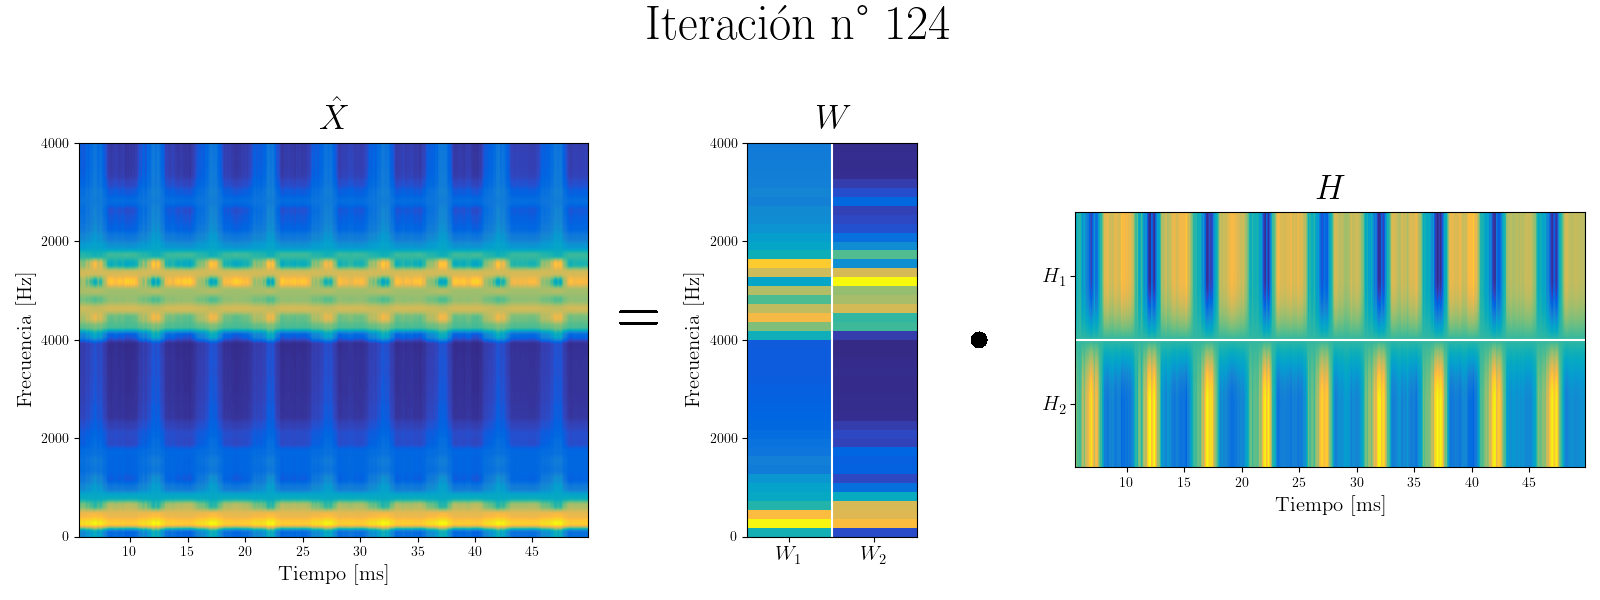

In [82]:
# Crear figura y ejes una sola vez
fig_, ax_ = plt.subplots(
1, 3,
figsize=(16, 6),
gridspec_kw={'width_ratios': [30, 10, 30]}
)
plt.subplots_adjust(wspace=0.55)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

cmap = Funciones.parula_map
for i in range(resultado_CONMF.n_iteraciones+1):
#Limpiar cada eje antes de redibujar
    for a in ax_:
        a.cla()

    # ============================================================
    # 1. Matriz X
    # ============================================================
#i = -1
    ax_[0].imshow(
        resultado_CONMF.proceso_espectrograma_aprox_plot[i],
        cmap=cmap, origin='lower', aspect='auto',
        extent=[resultado_NMF_speech.to_espectrograma,
                resultado_NMF_speech.tf_espectrograma,
                resultado_NMF_speech.fo_espectrograma,
                2*resultado_NMF_speech.ff_espectrograma]
    )
    ax_[0].set_title(r'$\hat{X}$', fontsize=25, pad=10)
    ax_[0].set_xlabel('Tiempo [ms]', fontsize=15)
    ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
    yticks = [0, 2000, 4000, 6000, 8000]
    ax_[0].set_yticks(yticks)
    ax_[0].set_yticklabels(['0', '2000', '4000', '2000', '4000'])

    # ============================================================
    # 2. Matriz W
    # ============================================================
    fila1_w = np.concatenate((resultado_CONMF.proceso_W1_acc[i],
                                resultado_CONMF.proceso_W1_speech[i]))
    fila2_w = np.concatenate((resultado_CONMF.proceso_W2_acc[i],
                                resultado_CONMF.proceso_W2_speech[i]))
    matriz_w = np.column_stack((fila1_w, fila2_w))

    ax_[1].imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                    extent=[0, 2,
                            resultado_NMF_speech.fo_espectrograma,
                            2*resultado_NMF_speech.ff_espectrograma])
    ax_[1].set_title(r'$W$', fontsize=25, pad=10)
    ax_[1].set_ylabel('Frecuencia [Hz]', fontsize=15)
    ax_[1].axvline(1, color='white', linewidth=1.5)
    ax_[1].set_xticks([0.5, 1.5])
    ax_[1].set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)
    ax_[1].set_yticks(yticks)
    ax_[1].set_yticklabels(['0', '2000', '4000', '2000', '4000'])
    # ============================================================
    # 3. Matriz H
    # ============================================================
    matriz_h = np.vstack((resultado_CONMF.proceso_H1[i],
                            resultado_CONMF.proceso_H2[i]))
    ax_[2].imshow(matriz_h, cmap=cmap, origin='lower', aspect='auto',
                    extent=[resultado_NMF_speech.to_espectrograma,
                            resultado_NMF_speech.tf_espectrograma, 0, 2])
    ax_[2].set_title(r'$H$', fontsize=25, pad=10)
    ax_[2].set_yticks([0.5, 1.5])
    ax_[2].set_yticklabels([r'$H_2$', r'$H_1$'], fontsize=15)
    ax_[2].axhline(1, color='white', linewidth=1.5)
    ax_[2].set_box_aspect(0.5)
    ax_[2].set_xlabel('Tiempo [ms]', fontsize=15)
    # Texto entre figuras
    fig_.text(0.40, 0.47, r'$=$', fontsize=45, ha='center', va='center')
    fig_.text(0.62, 0.47, r'$\cdot$', fontsize=110, ha='center', va='center')

    # Título general
    fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.subplots_adjust(wspace=0.4)   # aumenta el espacio entre columnas
    plt.savefig(f'Animacion presentacion/Animacion CONMF/{i}.pdf', bbox_inches='tight')


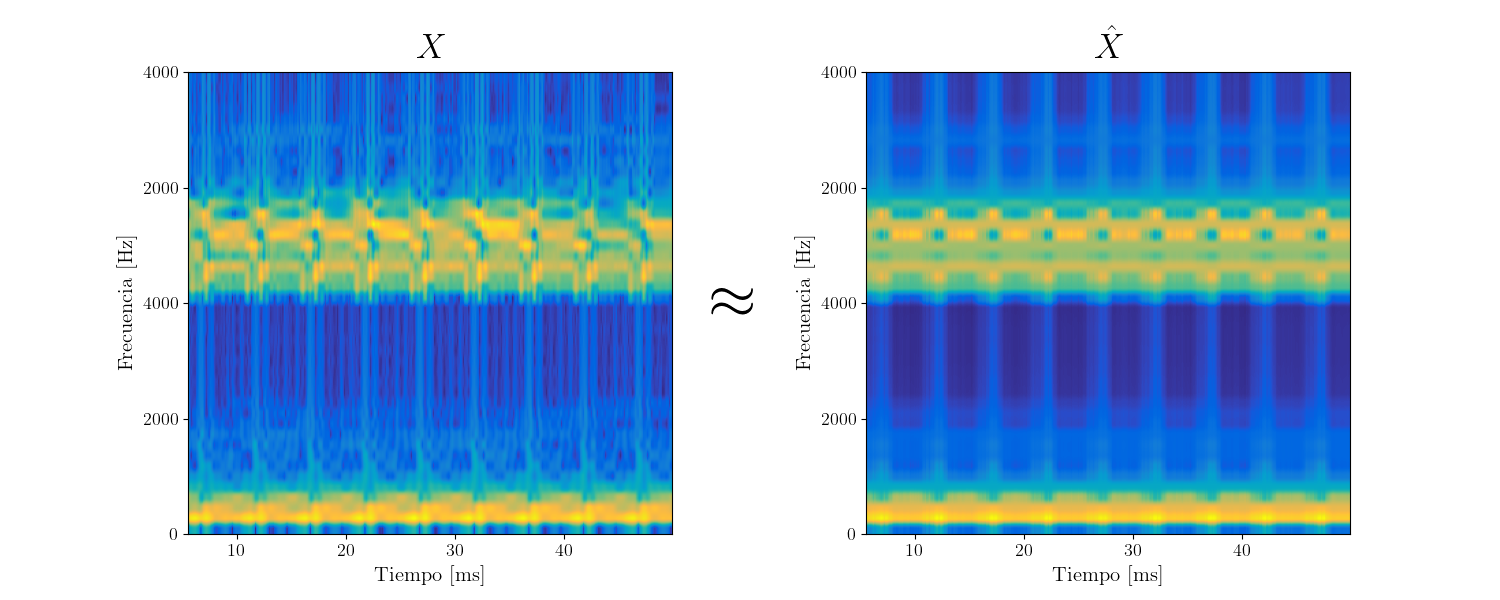

In [51]:
fig_, ax_ = plt.subplots(1,2,
figsize=(15, 6))
plt.subplots_adjust(wspace=0.40)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

i = 1
ax_[0].imshow(resultado_CONMF.espectrograma_plot_sincronizado,
    cmap=cmap, origin='lower', aspect='auto',
    extent=[resultado_NMF_speech.to_espectrograma,
            resultado_NMF_speech.tf_espectrograma,
            resultado_NMF_speech.fo_espectrograma,2*
            resultado_NMF_speech.ff_espectrograma]
)
ax_[0].set_title(r'$X$', fontsize=25, pad=10)
ax_[0].set_xlabel('Tiempo [ms]', fontsize=15)
ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[0].tick_params(axis='x', labelsize=13)
ax_[0].tick_params(axis='y', labelsize=13)
yticks = [0, 2000, 4000, 6000, 8000]
ax_[0].set_yticks(yticks)
ax_[0].set_yticklabels(['0', '2000', '4000', '2000', '4000'])

ax_[1].imshow(resultado_CONMF.espectrograma_aprox_plot,
    cmap=cmap, origin='lower', aspect='auto',
    extent=[resultado_NMF_speech.to_espectrograma,
            resultado_NMF_speech.tf_espectrograma,
            resultado_NMF_speech.fo_espectrograma,2*
            resultado_NMF_speech.ff_espectrograma]
)
ax_[1].set_title(r'$\hat{X}$', fontsize=25, pad=10)
ax_[1].set_xlabel('Tiempo [ms]', fontsize=15)
ax_[1].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[1].tick_params(axis='x', labelsize=13)
ax_[1].tick_params(axis='y', labelsize=13)
yticks = [0, 2000, 4000, 6000, 8000]
ax_[1].set_yticks(yticks)
ax_[1].set_yticklabels(['0', '2000', '4000', '2000', '4000'])
fig_.text(0.49, 0.5, r'$\approx$', fontsize=45, ha='center', va='center')
plt.savefig(f'Animacion presentacion/aproximacion_CONMF.pdf', bbox_inches='tight')

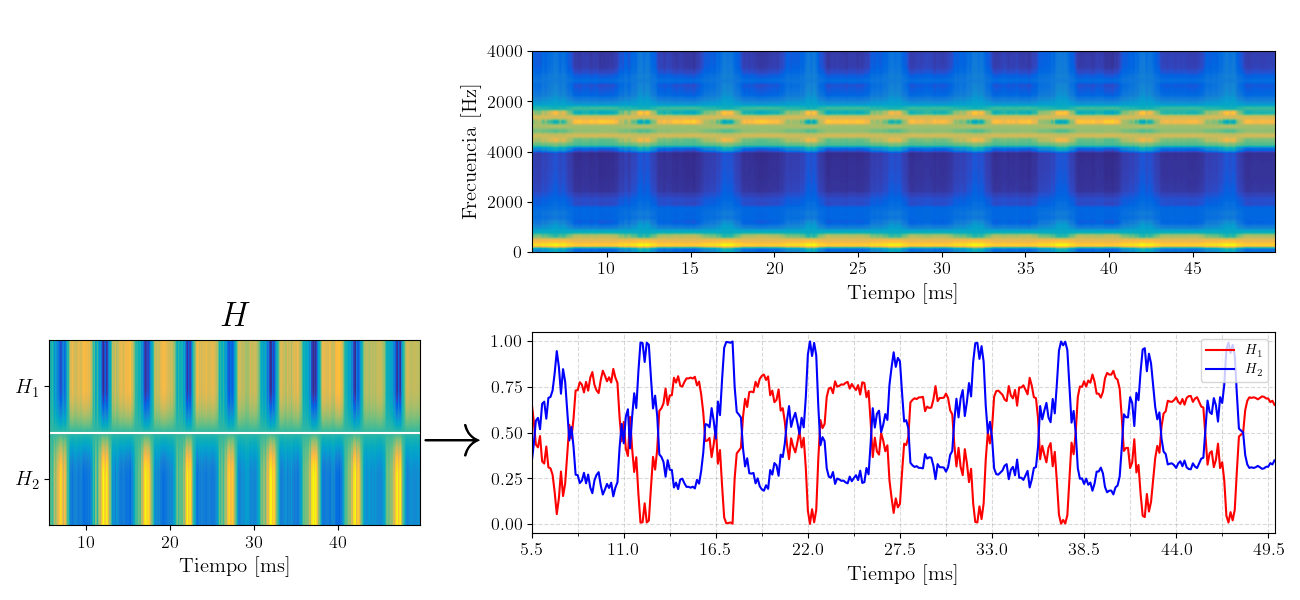

In [76]:
fig_, ax_ = plt.subplots(2,2,
figsize=(13, 6),
gridspec_kw={'width_ratios': [0.5,1]}
)
plt.subplots_adjust(hspace=0.30)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']


#for i in range(resultado_NMF_speech.n_iteraciones+1):
#        for i_ in range(0,2):
#                for j in range(0,2):
#                        ax_[i_][j].cla()
i = -1
ax_[0,0].axis('off') 
matriz_h = np.vstack((resultado_CONMF.proceso_H1[i],
                            resultado_CONMF.proceso_H2[i]))
ax_[1][0].imshow(matriz_h, cmap=cmap, origin='lower', aspect='auto',
                extent=[resultado_NMF_speech.to_espectrograma,
                        resultado_NMF_speech.tf_espectrograma, 0, 2])
ax_[1][0].set_title(r'$H$', fontsize=25, pad=10)
ax_[1][0].set_yticks([0.5, 1.5])
ax_[1][0].set_yticklabels([r'$H_2$', r'$H_1$'], fontsize=15)
ax_[1][0].axhline(1, color='white', linewidth=1.5)
ax_[1][0].set_box_aspect(0.5)
ax_[1][0].set_xlabel('Tiempo [ms]', fontsize=15)
ax_[1][0].tick_params(axis='x', labelsize=13);


ax_[0][1].imshow(resultado_CONMF.proceso_espectrograma_aprox_plot[i],
                cmap=cmap,
                origin='lower',
                aspect='auto',
                extent=[resultado_NMF_speech.to_espectrograma, resultado_NMF_speech.tf_espectrograma,
                        resultado_NMF_speech.fo_espectrograma, 2*resultado_NMF_speech.ff_espectrograma])
ax_[0][1].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[0][1].set_xlabel("Tiempo [ms]", fontsize=15)
ax_[0][1].tick_params(axis='x', labelsize=13);
ax_[0][1].tick_params(axis='y', labelsize=13);
yticks = [0, 2000, 4000, 6000, 8000]
ax_[0][1].set_yticks(yticks)
ax_[0][1].set_yticklabels(['0', '2000', '4000', '2000', '4000'])


ax_[1][1].plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.proceso_H2[i],color=color1,label=r'$H_1$')
ax_[1][1].plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.proceso_H1[i],color=color2,label=r'$H_2$')
ax_[1][1].set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
ax_[1][1].set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana))
ax_[1][1].set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana/2),minor=True)
ax_[1][1].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
ax_[1][1].legend(loc=legend_loc)
ax_[1][1].set_xlabel('Tiempo [ms]', fontsize=15);
ax_[1][1].tick_params(axis='x', labelsize=13);
ax_[1][1].tick_params(axis='y', labelsize=13);



#fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.40,wspace=0.20)   # aumenta el espacio entre columnas
fig_.text(0.35, 0.25, r'$\rightarrow$', fontsize=45, ha='center', va='center')
plt.savefig(f'Animacion presentacion/CONMF H.pdf', bbox_inches='tight')

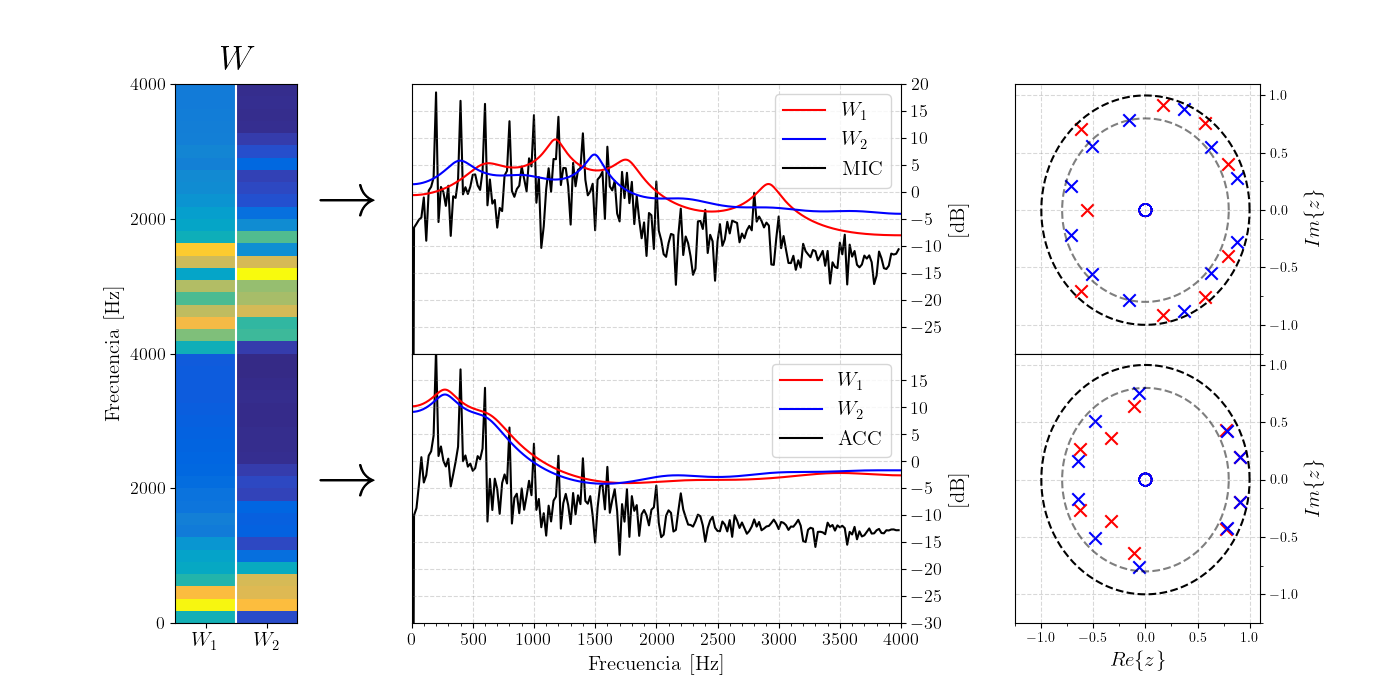

In [81]:

fig = plt.figure(figsize=(14,7))

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

# Definir la grilla: 2 filas, 3 columnas
# width_ratios controla los anchos relativos
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 2])
gs.update(hspace=0,wspace=0.40)
# Subplot que ocupa las dos filas de la primera columna
ax0 = fig.add_subplot(gs[:, 0])   # ":" significa todas las filas

# Subplots normales en la segunda y tercera columna
ax1 = fig.add_subplot(gs[0, 1])
ax2= fig.add_subplot(gs[1, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4= fig.add_subplot(gs[1, 2])
ax1.set_xticklabels([])
ax3.set_xticklabels([])
fila1_w = np.concatenate((resultado_CONMF.proceso_W1_acc[i],
                            resultado_CONMF.proceso_W1_speech[i]))
fila2_w = np.concatenate((resultado_CONMF.proceso_W2_acc[i],
                            resultado_CONMF.proceso_W2_speech[i]))
matriz_w = np.column_stack((fila1_w, fila2_w))

ax0.imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                extent=[0, 2,
                        resultado_NMF_speech.fo_espectrograma,
                        2*resultado_NMF_speech.ff_espectrograma])
ax0.set_title(r'$W$', fontsize=25, pad=10)
ax0.set_ylabel('Frecuencia [Hz]', fontsize=15)
ax0.axvline(1, color='white', linewidth=1.5)
ax0.set_xticks([0.5, 1.5])
ax0.set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)
yticks = [0, 2000, 4000, 6000, 8000]
ax0.set_yticks(yticks)
ax0.set_yticklabels(['0', '2000', '4000', '2000', '4000'], fontsize=13)

#========================= Respuesta en frecuencia/polos-ceros speech
# ------------- Respuesta en frecuencia
fs_r = 8000
theta = np.linspace(0, 2*np.pi, 200)
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],resultado_NMF_speech.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],resultado_NMF_speech.a_W2,fs=fs_r)
ax1.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
ax1.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
ax1.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='MIC', color=color3, zorder=-1)
ax1.set_xlim(0,fs_r/2)
ax1.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
ax1.grid(True, linestyle='dashed', color='gray', alpha=0.3)
ax1.set_xlabel('Frecuencia [Hz]',fontsize=15)
ax1.set_ylabel('[dB]',fontsize=15)
ax1.set_ylim([-30,20])
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")
ax1.tick_params(axis='y', labelsize=13);
ax1.legend(loc='upper right',fontsize=15)
# ------------- Polos y ceros   
ax3.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
ax3.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
ax3.yaxis.tick_right()
ax3.yaxis.set_label_position("right")
ax3.scatter(np.real(resultado_NMF_speech.ceros_W1), np.imag(resultado_NMF_speech.ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax3.scatter(np.real(resultado_NMF_speech.polos_W1), np.imag(resultado_NMF_speech.polos_W1),s=80, marker='x', color=color1, label='Polos')
ax3.scatter(np.real(resultado_NMF_speech.ceros_W2), np.imag(resultado_NMF_speech.ceros_W2),s=80, facecolors='none', edgecolors=color2, label='Ceros')
ax3.scatter(np.real(resultado_NMF_speech.polos_W2), np.imag(resultado_NMF_speech.polos_W2),s=80, marker='x', color=color2, label='Polos')
ax3.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
ax3.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
ax3.set_ylabel(r"$Im\{z\}$",fontsize=15)
ax3.set_xlabel(r"$Re\{z\}$",fontsize=15)
ax3.grid(True, linestyle='dashed', color='gray', alpha=0.3)

#========================= Respuesta en frecuencia/polos-ceros acc
# ------------- Respuesta en frecuencia
theta = np.linspace(0, 2*np.pi, 200)
fftseñal, fseñal = Funciones.FFT(señal_ACC, fs_r)
fw1,hw1 = sig.freqz([1],resultado_NMF_acc.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],resultado_NMF_acc.a_W2,fs=fs_r)
ax2.plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
ax2.plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
ax2.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='ACC', color=color3, zorder=-1)
ax2.set_xlim(0,fs_r/2)
ax2.set_xticks(np.arange(0, fs_r/2, 100), minor=True)
ax2.grid(True, linestyle='dashed', color='gray', alpha=0.3)
ax2.set_xlabel('Frecuencia [Hz]',fontsize=15)
ax2.set_ylabel('[dB]',fontsize=15)
ax2.set_ylim([-30,20])
ax2.legend(loc='upper right',fontsize=15)
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.tick_params(axis='x', labelsize=13);
ax2.tick_params(axis='y', labelsize=13);
# ------------- Polos y ceros   
ax4.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
ax4.plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
ax4.yaxis.tick_right()
ax4.yaxis.set_label_position("right")
ax4.scatter(np.real(resultado_NMF_acc.ceros_W1), np.imag(resultado_NMF_acc.ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax4.scatter(np.real(resultado_NMF_acc.polos_W1), np.imag(resultado_NMF_acc.polos_W1),s=80, marker='x', color=color1, label='Polos')
ax4.scatter(np.real(resultado_NMF_acc.ceros_W2), np.imag(resultado_NMF_acc.ceros_W2),s=80, facecolors='none', edgecolors=color2, label='Ceros')
ax4.scatter(np.real(resultado_NMF_acc.polos_W2), np.imag(resultado_NMF_acc.polos_W2),s=80, marker='x', color=color2, label='Polos')
ax4.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
ax4.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
ax4.set_ylabel(r"$Im\{z\}$",fontsize=15)
ax4.set_xlabel(r"$Re\{z\}$",fontsize=15)
ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3)

fig.text(0.25, 0.30, r'$\rightarrow$', fontsize=45, ha='center', va='center')
fig.text(0.25, 0.70, r'$\rightarrow$', fontsize=45, ha='center', va='center')
from matplotlib.ticker import MaxNLocator

ax1.yaxis.set_major_locator(MaxNLocator(prune='lower'))

# ax2 es el de abajo: podamos su tick superior (el que choca con ax1)
ax2.yaxis.set_major_locator(MaxNLocator(prune='upper'))
plt.savefig(f'Animacion presentacion/CONMF W.pdf', bbox_inches='tight')
# ax1 es el de arriba: podamos su tick inferior (el que choca con ax2)


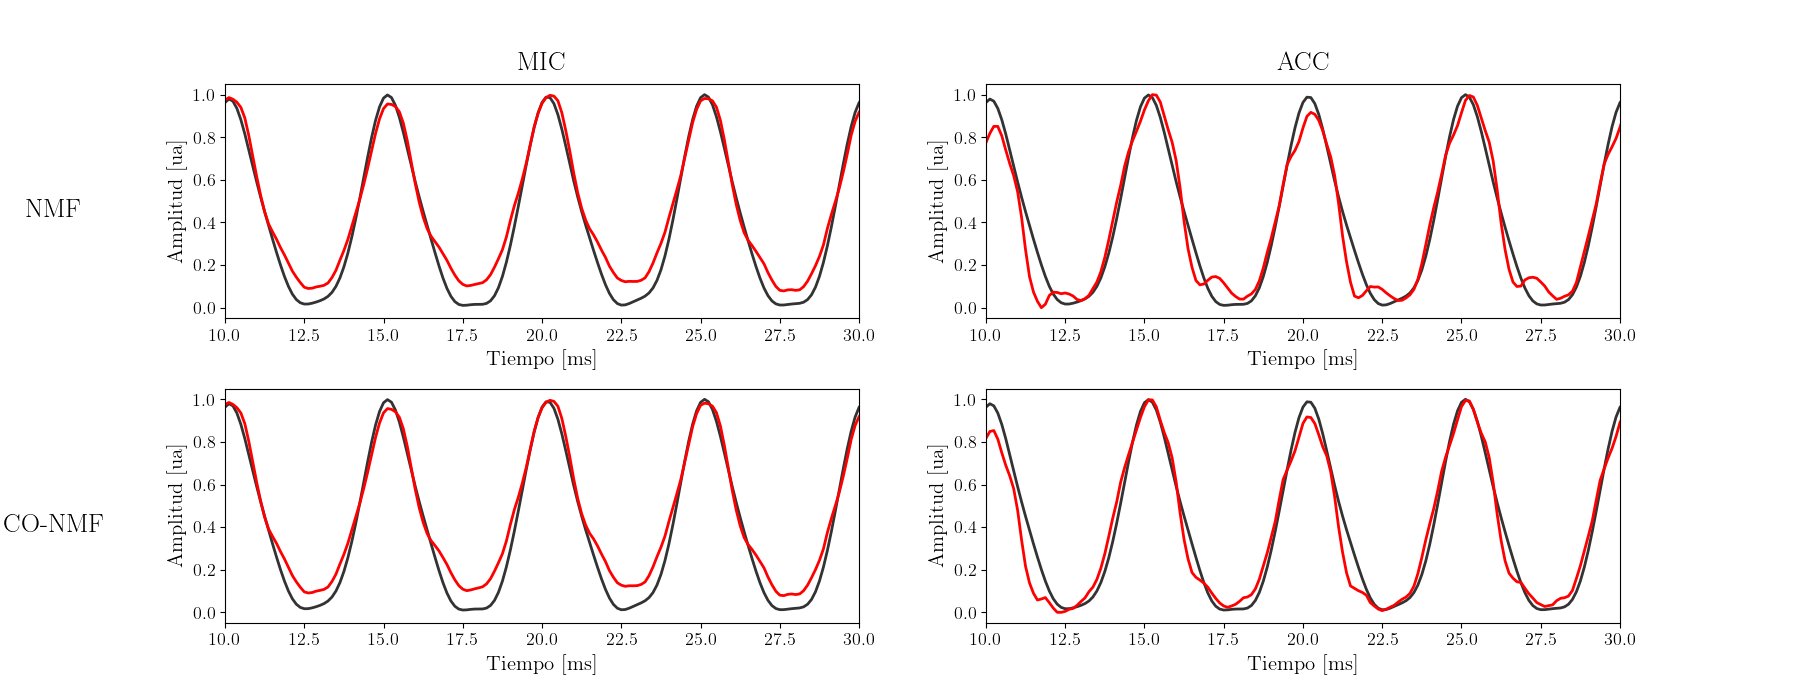

In [33]:
fig,ax = plt.subplots(2,2,figsize=(18,7))
plt.subplots_adjust(hspace=0.30)
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']
for i_ in range(0,2):
    for j in range(0,2):
        ax[i_][j].set_xlabel('Tiempo [ms]', fontsize=15);
        ax[i_][j].set_ylabel('Amplitud [ua]', fontsize=15);
        ax[i_][j].tick_params(axis='x', labelsize=13);
        ax[i_][j].tick_params(axis='y', labelsize=13);
        ax[i_][j].set_xlim([10,30]);
        ax[i_][j].plot(tiempos_analisis,flujo_OVV,color='k', alpha=0.8,linewidth=2)
se,sr,t= Funciones.Sincronizar2(resultado_NMF_speech.flujo1,flujo_OVV,tiempos_analisis)
ax[0][0].plot(t,se,color=color1,label="Solucion 1",linewidth=2)
ax[0][0].set_title('MIC',fontsize=19,pad=10)
se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo1_speech,flujo_OVV,tiempos_analisis)
ax[1][0].plot(t,se,color=color1,label="Solucion 1",linewidth=2)

se,sr,t= Funciones.Sincronizar2(resultado_NMF_acc.flujo1,flujo_OVV,tiempos_analisis)
ax[0][1].plot(t,se,color=color1,label="Solucion 1",linewidth=2)
ax[0][1].set_title('ACC',fontsize=19,pad=10)
se,sr,t= Funciones.Sincronizar2(resultado_CONMF.flujo1_acc,flujo_OVV,tiempos_analisis)
ax[1][1].plot(t,se,color=color1,label="Solucion 1",linewidth=2)

fig.text(0.03, 0.70, r'NMF', fontsize=19, ha='center', va='center')
fig.text(0.03, 0.25, r'CO-NMF', fontsize=19, ha='center', va='center')
plt.savefig(f'Animacion presentacion/Resultado CONMF.pdf', bbox_inches='tight')


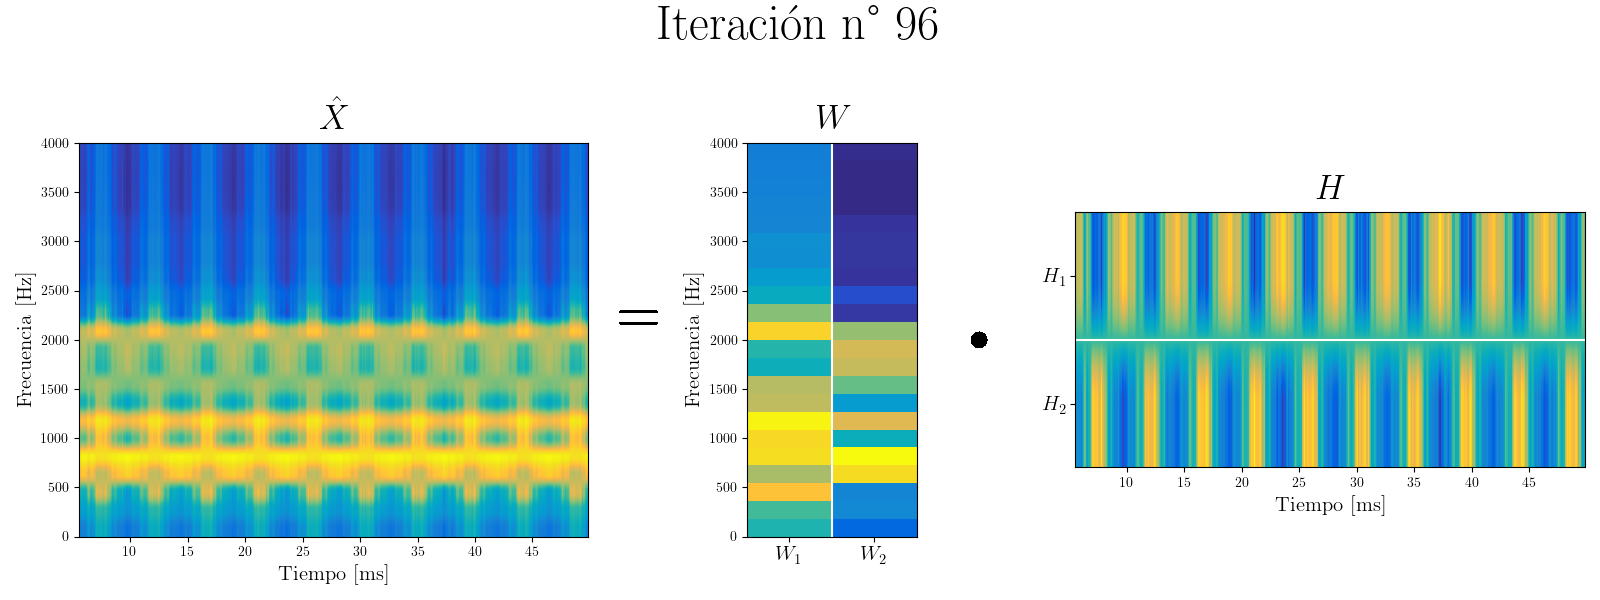

In [3]:
# Crear figura y ejes una sola vez
fig_, ax_ = plt.subplots(
1, 3,
figsize=(16, 6),
gridspec_kw={'width_ratios': [30, 10, 30]}
)
plt.subplots_adjust(wspace=0.55)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

cmap = Funciones.parula_map
for i in range(resultado_CONMF.n_iteraciones+1):
#Limpiar cada eje antes de redibujar
    for a in ax_:
        a.cla()

    # ============================================================
    # 1. Matriz X
    # ============================================================
    #i = 1
    ax_[0].imshow(resultado_NMF_speech.proceso_espectrograma_aprox[i],
        cmap=cmap, origin='lower', aspect='auto',
        extent=[resultado_NMF_speech.to_espectrograma,
                resultado_NMF_speech.tf_espectrograma,
                resultado_NMF_speech.fo_espectrograma,
                resultado_NMF_speech.ff_espectrograma]
    )
    ax_[0].set_title(r'$\hat{X}$', fontsize=25, pad=10)
    ax_[0].set_xlabel('Tiempo [ms]', fontsize=15)
    ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)

    # ============================================================
    # 2. Matriz W
    # ============================================================

    matriz_w = np.column_stack((resultado_NMF_speech.proceso_W1[i], resultado_NMF_speech.proceso_W2[i]))

    ax_[1].imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                    extent=[0, 2,
                            resultado_NMF_speech.fo_espectrograma,
                            resultado_NMF_speech.ff_espectrograma])
    ax_[1].set_title(r'$W$', fontsize=25, pad=10)
    ax_[1].set_ylabel('Frecuencia [Hz]', fontsize=15)
    ax_[1].axvline(1, color='white', linewidth=1.5)
    ax_[1].set_xticks([0.5, 1.5])
    ax_[1].set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)

    # ============================================================
    # 3. Matriz H
    # ============================================================
    matriz_h = np.vstack((resultado_NMF_speech.proceso_H1[i],
                            resultado_NMF_speech.proceso_H2[i]))
    ax_[2].imshow(matriz_h, cmap=cmap, origin='lower', aspect='auto',
                    extent=[resultado_NMF_speech.to_espectrograma,
                            resultado_NMF_speech.tf_espectrograma, 0, 2])
    ax_[2].set_title(r'$H$', fontsize=25, pad=10)
    ax_[2].set_yticks([0.5, 1.5])
    ax_[2].set_yticklabels([r'$H_2$', r'$H_1$'], fontsize=15)
    ax_[2].axhline(1, color='white', linewidth=1.5)
    ax_[2].set_box_aspect(0.5)
    ax_[2].set_xlabel('Tiempo [ms]', fontsize=15)
    # Texto entre figuras
    fig_.text(0.40, 0.47, r'$=$', fontsize=45, ha='center', va='center')
    fig_.text(0.62, 0.47, r'$\cdot$', fontsize=110, ha='center', va='center')

    # Título general
    fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.subplots_adjust(wspace=0.4)   # aumenta el espacio entre columnas
    plt.savefig(f'Animacion presentacion/{i}.pdf', bbox_inches='tight')

NameError: name 'señal_MBK' is not defined

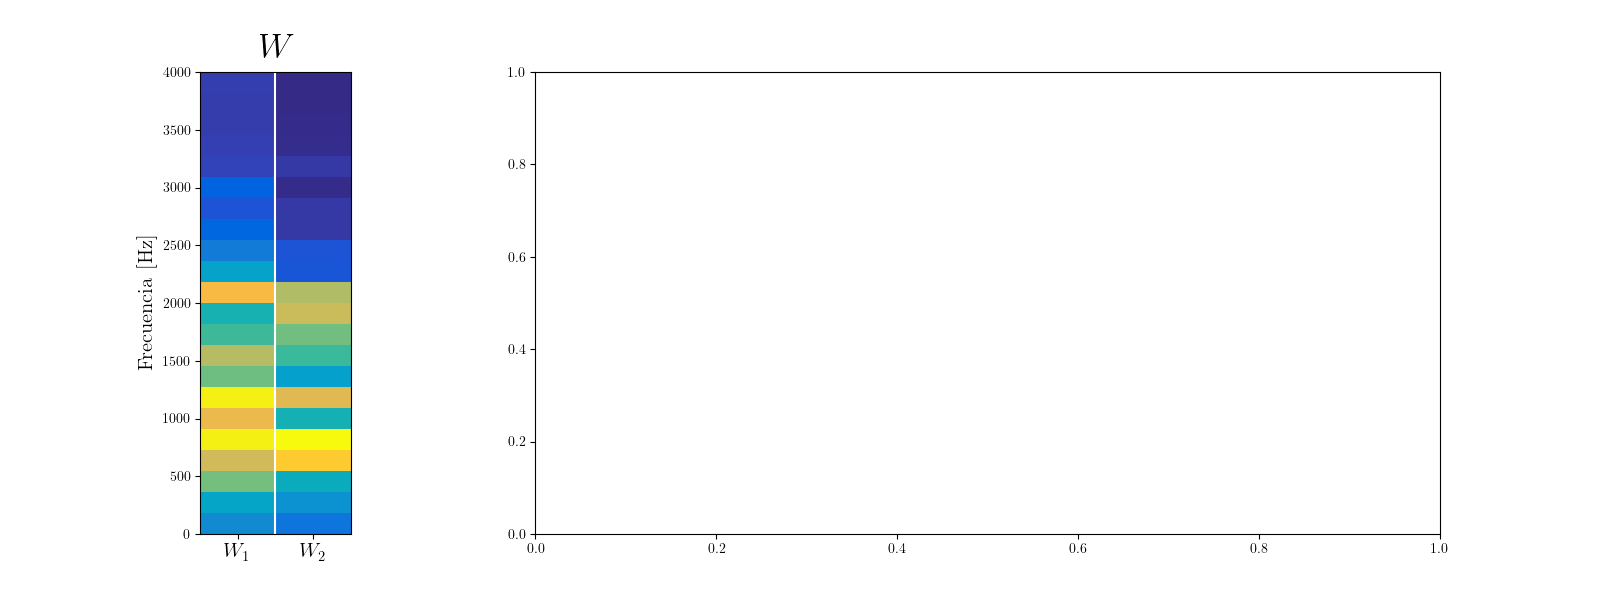

In [6]:
# Crear figura y ejes una sola vez
fig_, ax_ = plt.subplots(1,2,
figsize=(16, 6),
gridspec_kw={'width_ratios': [10, 60]}
)
plt.subplots_adjust(wspace=0.35)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

cmap = Funciones.parula_map
#for i in range(resultado_CONMF.n_iteraciones+1):
#Limpiar cada eje antes de redibujar
#    for a in ax_:
#        a.cla()


i = 1

matriz_w = np.column_stack((resultado_NMF_speech.proceso_W1[i], resultado_NMF_speech.proceso_W2[i]))

ax_[0].imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                extent=[0, 2,
                        resultado_NMF_speech.fo_espectrograma,
                        resultado_NMF_speech.ff_espectrograma])
ax_[0].set_title(r'$W$', fontsize=25, pad=10)
ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[0].axvline(1, color='white', linewidth=1.5)
ax_[0].set_xticks([0.5, 1.5])
ax_[0].set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)
fs_r = 8000
# ------------- Respuesta en frecuencia
theta = np.linspace(0, 2*np.pi, 200)
fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
fw1,hw1 = sig.freqz([1],resultado_NMF_speech.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],resultado_NMF_speech.a_W2,fs=fs_r)
ax_[1].plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$', color=color1)
ax_[1].plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
ax_[1].plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
ax_[1].set_xlim(0,fs_r/2)
ax_[1].set_xticks(np.arange(0, fs_r/2, 100), minor=True)
ax_[1].grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
ax_[1].set_xlabel('Frecuencia [Hz]')
ax_[1].set_ylabel('[dB]')
ax_[1].set_ylim([-30,20])
ax_[1].legend(loc='upper right')
#plt.savefig(f'Animacion presentacion/{i}.pdf', bbox_inches='tight')